<a href="https://colab.research.google.com/github/danah113/IT326-Data-mining-Project/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IT326 Data Mining Project: Phase 3 (Final Report)



## [1] Problem
This project analyzes the Mushroom dataset to investigate whether the physical characteristics of a mushroom can be used to distinguish edible mushrooms from poisonous ones. The dataset contains categorical features describing different parts and properties of mushrooms, including cap shape, cap surface, cap color, odor, gill characteristics, stalk characteristics, veil and ring properties, spore-print color, population, and habitat. The project will apply classification techniques to predict whether a mushroom is edible or poisonous and clustering techniques to group mushrooms with similar physical characteristics. The resulting clusters will also be examined to determine how closely the discovered groups correspond to the known edibility classes.<br>
We chose this dataset because mushrooms have a wide variety of physical characteristics, which makes them interesting to analyze and compare. Studying these characteristics is important because some mushrooms may share similar features while having different levels of edibility. Analyzing the data can help discover useful patterns, show similarities between mushrooms, and identify features related to whether they are edible or poisonous.


## [2] Data Mining Task
The goal of this project is to apply classification and clustering techniques to the Mushroom dataset.
For the classification task, the objective is to build and evaluate models that predict the target class, edible (e) or poisonous (p), using the 22 categorical physical and environmental features.<br>
For the clustering task, the objective is to group mushroom instances according to similarities in their characteristics without using the class label during cluster formation, and then examine the relationship between the resulting clusters and the actual edibility classes. <br>
The project also aims to prepare the data appropriately by handling missing values and encoding categorical attributes before applying the selected data mining algorithms.


## [3] Data
>This dataset was obtained from the UCI Machine Learning Repository:
Mushroom [Dataset]. (1981). UCI Machine Learning Repository. https://doi.org/10.24432/C5959T.

In [ ]:
import pandas as pd
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

mushroom = fetch_ucirepo(id=73)

X = mushroom.data.features   # columns
y = mushroom.data.targets    # rows
df = pd.concat([X, y], axis=1)

###Dataset Description:

In [ ]:
#Features and records:
print('This dataset consists of the following number of rows and columns:')   #including the class lable'poisonous'
print('Rows: ', df.shape[0], '\nColumns: ', df.shape[1])
print('Data types of its attributes are:\n', df.dtypes)

This dataset consists of the following number of rows and columns:
Rows:  8124 
Columns:  23
Data types of its attributes are:
 cap-shape                   object
cap-surface                 object
cap-color                   object
bruises                     object
odor                        object
gill-attachment             object
gill-spacing                object
gill-size                   object
gill-color                  object
stalk-shape                 object
stalk-root                  object
stalk-surface-above-ring    object
stalk-surface-below-ring    object
stalk-color-above-ring      object
stalk-color-below-ring      object
veil-type                   object
veil-color                  object
ring-number                 object
ring-type                   object
spore-print-color           object
population                  object
habitat                     object
poisonous                   object
dtype: object


In [ ]:
#class Attribute:
print('Class values:', df['poisonous'].unique())
print('\nCount of instances per class:')
print(df['poisonous'].value_counts())


Class values: ['p' 'e']

Count of instances per class:
poisonous
e    4208
p    3916
Name: count, dtype: int64


In [ ]:
#Sample of the Raw Dataset:
df.head()


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,poisonous
0,x,s,n,t,p,f,c,n,k,e,...,w,w,p,w,o,p,k,s,u,p
1,x,s,y,t,a,f,c,b,k,e,...,w,w,p,w,o,p,n,n,g,e
2,b,s,w,t,l,f,c,b,n,e,...,w,w,p,w,o,p,n,n,m,e
3,x,y,w,t,p,f,c,n,n,e,...,w,w,p,w,o,p,k,s,u,p
4,x,s,g,f,n,f,w,b,k,t,...,w,w,p,w,o,e,n,a,g,e


###Missing values and their analysis & Statistical summaries:
>The dataset contains a single column with missing values: stalk-root, which has 2,480 missing entries out of 8,124 total rows (about 30.5%). All other 21 attributes are fully complete. <br>Notably, while the original UCI file represents missing values using the symbol '?', the ucimlrepo package we used already converts these into standard NaN values automatically, which is why our direct '?' search returned zero across all columns. <br>Since missing values are concentrated so heavily in one attribute and represent a substantial portion of the dataset, dropping these rows would discard nearly a third of our data.<br> During preprocessing, we will therefore consider treating the missing values as their own category rather than removing the affected rows.

In [ ]:
print("Standard NaN missing values:")
print(df.isnull().sum())


Standard NaN missing values:
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
poisonous                      0
dtype: int64


In [ ]:
print("\n'?' values per column:")
print((df == '?').sum())


'?' values per column:
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
poisonous                   0
dtype: int64


In [ ]:
df.describe(include='object') #Statistical summary for categorical data

,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,poisonous
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,6,4,10,2,9,2,2,2,12,2,...,9,9,1,4,3,5,9,6,7,2
top,x,y,n,f,n,f,c,b,b,t,...,w,w,p,w,o,p,w,v,d,e
freq,3656,3244,2284,4748,3528,7914,6812,5612,1728,4608,...,4464,4384,8124,7924,7488,3968,2388,4040,3148,4208


#### Statistical summary (categorical attributes)

> **“Added after Phase 2 feedback”**

<br>
All 23 columns in this dataset (22 features and the `poisonous` class label) are categorical, so a five-number summary, boxplots and outlier detection do not apply. Instead we used `describe(include='object')`, which reports the count, number of unique values, the most frequent value (top) and its frequency.<br>
- **Completeness:** all columns shown have 8,124 records. The only incomplete attribute is `stalk-root`, which has 2,480 missing values (see the missing values analysis above).<br>
- **Cardinality:** attributes range from 1 to 12 distinct values. `gill-color` has the most (12), followed by `cap-color` (10), then `odor`, `stalk-color-above-ring`, `stalk-color-below-ring` and `spore-print-color` (9 each).<br>
- **Dominant values:** several attributes are heavily dominated by one value. `gill-attachment` is `f` in 7,914 records (about 97.4%), `veil-color` is `w` in 7,924 (about 97.5%), `ring-number` is `o` in 7,488 (about 92.2%), and `gill-spacing` is `c` in 6,812 (about 83.9%).<br>
- **Constant attribute:** `veil-type` has only one unique value (`p`) across all 8,124 records, so it carries no information for distinguishing between classes.<br>
- **Class label:** `poisonous` has two values, `e` (edible) and `p` (poisonous).<br>

**Impact on preprocessing:** `veil-type` is a constant attribute and will be removed. Near-constant attributes such as `gill-attachment` and `veil-color` offer very little discriminating power and are candidates for feature selection.

In [ ]:
print(df['odor'].value_counts()) #Value counts for a few key columns
print(df['habitat'].value_counts())
print(df['poisonous'].value_counts())

odor
n    3528
f    2160
s     576
y     576
a     400
l     400
p     256
c     192
m      36
Name: count, dtype: int64
habitat
d    3148
g    2148
p    1144
l     832
u     368
m     292
w     192
Name: count, dtype: int64
poisonous
e    4208
p    3916
Name: count, dtype: int64


#### Value counts for key columns
> **“Added after Phase 2 feedback”**

- **odor (9 categories):** `n` (none) is the most common with 3,528 records (about 43.4%), followed by `f` (foul) with 2,160 (about 26.6%). `s` and `y` have 576 each, `a` and `l` have 400 each, `p` has 256, `c` has 192, and `m` is the rarest with 36. The distribution is uneven, and odor is likely to be an informative attribute for the classification task.<br>
- **habitat (7 categories):** `d` (woods) is the most common with 3,148 records, followed by `g` (grasses) with 2,148 and `p` (paths) with 1,144. `l`, `u`, `m` and `w` are less common, with `w` having the fewest at 192.<br>
- **poisonous (class label):** `e` (edible) has 4,208 records (about 51.8%) and `p` (poisonous) has 3,916 (about 48.2%). The classes are nearly balanced, so no resampling is needed for classification.<br>

In [ ]:
df.to_csv("Raw_dataset.csv", index=False)
from google.colab import files
files.download("Raw_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###Class distribution plot:

>To analyze the class label distribution, a bar chart was used to visualize the
distribution of the poisonous class label in the dataset.

Class Counts:
poisonous
e    4208
p    3916
Name: count, dtype: int64

Class Percentages:
poisonous
e    51.8
p    48.2
Name: count, dtype: float64


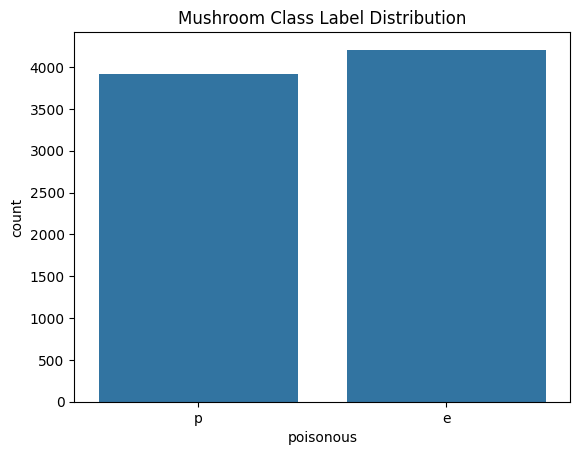

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

class_counts = df['poisonous'].value_counts()
class_percentages = (class_counts / len(df)) * 100

print("Class Counts:")
print(class_counts)

print("\nClass Percentages:")
print(class_percentages.round(2))

sns.countplot(x='poisonous', data=df)
plt.title('Mushroom Class Label Distribution')
plt.show()

>The class label distribution shows that the dataset contains 4,208 edible mushrooms (51.8%) and 3,916 poisonous mushrooms (48.2%). The two classes are relatively balanced because their counts and percentages are close. This information helped us determine that class balancing is not required during preprocessing, since neither class strongly dominates the dataset.

###Bar chart:
>To better understand the dataset, the distributions of selected features were examined. These visualizations provide an overview of how the data is distributed across different categories and help identify patterns, imbalances, or categories that occur more frequently than others. This information helps determine whether preprocessing steps are needed before further analysis.

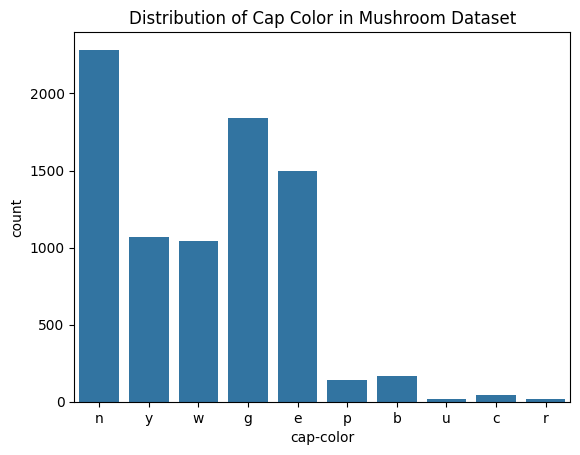

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='cap-color', data=df)
plt.title("Distribution of Cap Color in Mushroom Dataset")
plt.show()

>This bar plot shows the frequency of each cap-color category in the mushroom dataset. It provides information about the distribution of the different cap colors and allows us to identify categories that are more or less common. The categories have different frequencies, showing that the categorical values are not evenly distributed. Since cap-color is also a categorical attribute, it needs to be encoded into numerical values during preprocessing before it can be used effectively.

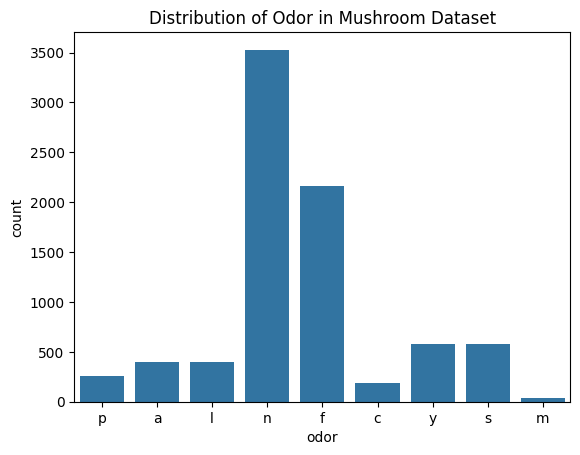

In [ ]:
sns.countplot(x='odor', data=df)
plt.title("Distribution of Odor in Mushroom Dataset")
plt.show()

>This bar plot shows the frequency of each odor category in the mushroom dataset. It provides information about how the observations are distributed across the different odor categories. The plot shows that some categories occur much more frequently than others, indicating an uneven distribution of the categorical values. Since odor is a categorical attribute, preprocessing is required to convert it into a numerical format through categorical encoding before it can be used in further analysis or machine-learning models.

###Pie chart:

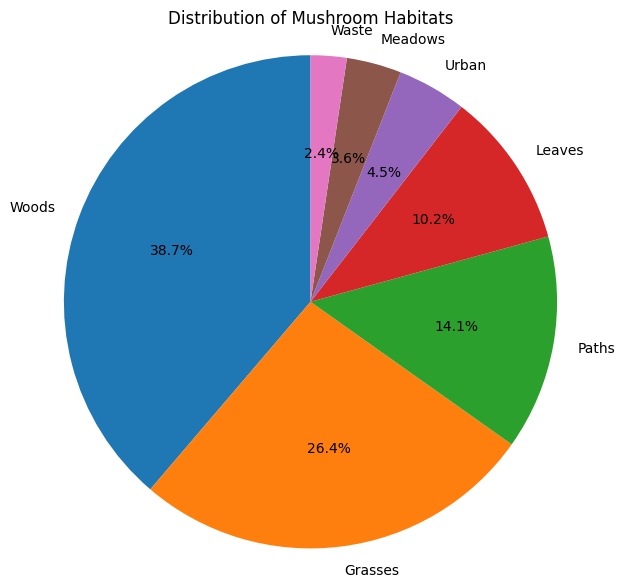

In [ ]:
import matplotlib.pyplot as plt

habitat_names = {

    'd': 'Woods',

    'g': 'Grasses',

    'p': 'Paths',

    'l': 'Leaves',

    'u': 'Urban',

    'm': 'Meadows',

    'w': 'Waste'

}

habitat_counts = df['habitat'].value_counts()

labels = [habitat_names[code] for code in habitat_counts.index]

plt.figure(figsize=(7, 7))

plt.pie(

    habitat_counts,

    labels=labels,

    autopct='%1.1f%%',

    startangle=90

)

plt.title('Distribution of Mushroom Habitats')

plt.axis('equal')

plt.show()

>This pie chart shows the percentage of mushrooms in each habitat category. Woods is the most common habitat (38.7%), followed by grasses (26.4%), while waste is the least common (2.4%). The categories are not equally represented. Since habitat is categorical, it needs encoding before it can be used in a machine-learning model.

## [4] Data Preprocessing




###Encoding & Missing value handling:






>**Encoding.** All attributes in the Mushroom dataset, including the class label, are nominal and stored as letters, while most ML algorithms require numeric input.

- Missing values in **stalk-root** were first replaced with a new category, "missing", to keep ~30% of the data.
- **Label Encoding** was applied to attributes with two or fewer values (e.g. bruises, gill-size), since 0/1 creates no false order.
- **One-Hot Encoding** was applied to attributes with more than two values (e.g. odor, habitat), to avoid implying an order between categories.
- The class label was mapped to edible = 0 and poisonous = 1.

**Result:** all columns are now numeric and ready for feature selection and modeling.


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
from sklearn.preprocessing import LabelEncoder
 ### Before Encoding
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()
df_encoded['stalk-root'] = df_encoded['stalk-root'].fillna('missing')

target = 'poisonous'
features = [c for c in df_encoded.columns if c != target]

print("Before encoding:")
display(df_encoded[['cap-shape', 'bruises', 'odor', 'stalk-root', 'habitat', target]].head())


Duplicate rows: 0
Before encoding:


,cap-shape,bruises,odor,stalk-root,habitat,poisonous
0,x,t,p,e,u,p
1,x,t,a,c,g,e
2,b,t,l,c,m,e
3,x,t,p,e,u,p
4,x,f,n,e,g,e


In [ ]:
	### Encoding
binary_cols = [c for c in features if df_encoded[c].nunique() <= 2]
multi_cols = [c for c in features if df_encoded[c].nunique() > 2]

for c in binary_cols:
    df_encoded[c] = LabelEncoder().fit_transform(df_encoded[c])

df_encoded = pd.get_dummies(df_encoded, columns=multi_cols, dtype=int)
df_encoded[target] = df_encoded[target].map({'e': 0, 'p': 1})

print("Label encoded:", binary_cols)
print("One-hot encoded:", multi_cols)
print("Shape before:", df.shape, "| Shape after:", df_encoded.shape)



Label encoded: ['bruises', 'gill-attachment', 'gill-spacing', 'gill-size', 'stalk-shape', 'veil-type']
One-hot encoded: ['cap-shape', 'cap-surface', 'cap-color', 'odor', 'gill-color', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']
Shape before: (8124, 23) | Shape after: (8124, 113)


In [ ]:
### After Encoding
print("After encoding:")
display(df_encoded.head())
print("Non-numeric columns left:", df_encoded.select_dtypes(exclude='number').columns.tolist())


After encoding:


,bruises,gill-attachment,gill-spacing,gill-size,stalk-shape,veil-type,poisonous,cap-shape_b,cap-shape_c,cap-shape_f,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,1,1,0,1,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0
1,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,1,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0
3,1,1,0,1,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0
4,0,1,1,0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


Non-numeric columns left: []


###Feature Selection:

>The Chi-Square (χ²) method was used with SelectKBest to identify the features that have the strongest relationship with the target variable (poisonous). The Chi-Square method is suitable for our categorical dataset because it measures the association between categorical features and the target class.<br>
We selected the top 15 features to reduce the number of features while keeping the most relevant information for the classification task.
<br>Result: 15 features were selected, and the final dataset contains 16 columns: 15 selected features plus the target variable (poisonous). Shape after feature selection: (8124, 16)

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2

df_processed = df_encoded.copy()

X_features = df_processed.drop(columns=['poisonous'])
y_target = df_processed['poisonous']

selector = SelectKBest(score_func=chi2, k=15)  # select the top 15 most relevant features
X_selected = selector.fit_transform(X_features, y_target)

selected_columns = X_features.columns[selector.get_support()]
print(f"Selected features ({len(selected_columns)}):")
print(list(selected_columns))

df_processed = pd.concat(
    [pd.DataFrame(X_selected, columns=selected_columns), y_target.reset_index(drop=True)],
    axis=1
)
print(f"Shape after feature selection: {df_processed.shape}")

Selected features (15):
['bruises', 'gill-spacing', 'gill-size', 'odor_f', 'odor_n', 'gill-color_b', 'stalk-surface-above-ring_k', 'stalk-surface-below-ring_k', 'ring-type_l', 'ring-type_p', 'spore-print-color_h', 'spore-print-color_k', 'spore-print-color_n', 'spore-print-color_w', 'population_v']
Shape after feature selection: (8124, 16)


In [ ]:
### Save the Final Preprocessed Dataset
df_processed.to_csv('Preprocessed_dataset.csv', index=False)
print(f"Saved Preprocessed_dataset.csv with shape {df_processed.shape}")
display(df_processed.head())

Saved Preprocessed_dataset.csv with shape (8124, 16)


,bruises,gill-spacing,gill-size,odor_f,odor_n,gill-color_b,stalk-surface-above-ring_k,stalk-surface-below-ring_k,ring-type_l,ring-type_p,spore-print-color_h,spore-print-color_k,spore-print-color_n,spore-print-color_w,population_v,poisonous
0,1,0,1,0,0,0,0,0,0,1,0,1,0,0,0,1
1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
2,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
3,1,0,1,0,0,0,0,0,0,1,0,1,0,0,0,1
4,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0


## [5] Data Mining Technique
### Classification <M5>
Decision Tree classification was applied to predict whether a mushroom is edible or poisonous. The `DecisionTreeClassifier` from the `sklearn.tree` package was used. Two attribute selection measures were applied: Gini index and Information Gain (entropy). Both methods were evaluated using three training/testing partitions: 90/10, 80/20, and 70/30. The same `random_state` was used for all partitions to make the results reproducible and the comparison fair. Decision Tree classification was selected because the project problem is a classification task with a categorical class label.



### Clustering <M4>
K-means clustering (`sklearn.cluster.KMeans`) was used to group the mushrooms by similarity, without using the class label. K-means is suitable because all attributes are numeric after preprocessing, and it groups records by their distance to cluster centers. It is also simple and fast on our 8,124 records. The 15 selected features were standardized with StandardScaler, and the `poisonous` label was removed before clustering and used only afterwards to compare the clusters with edibility.<br>
We ran K-means with three values of K (2, 4 and 6) and evaluated each one using the average silhouette width and the total within-cluster sum of squares, which is read with an elbow plot, with the Calinski-Harabasz index as an extra check. The clusters were visualized for each K, and the best K was chosen by majority rule across these criteria. A fixed random_state=42 with 10 restarts was used so the results are reproducible.


## [6] Evaluation and Comparison
### 6.1 Classification: Gini index <M2>

Gini - 90/10 Split
Accuracy: 1.0
Confusion Matrix:
[[421   0]
 [  0 392]]


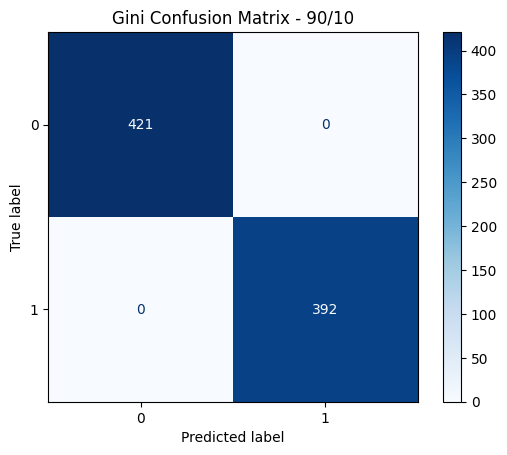

In [ ]:


from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use encoded data before feature selection
X = df_encoded.drop(columns=['poisonous'])
y = df_encoded['poisonous']

# Split: 90% training, 10% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)

# Select features using training data only
selector = SelectKBest(score_func=chi2, k=15)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Train Gini Decision Tree
gini_90 = DecisionTreeClassifier(criterion='gini', random_state=42)
gini_90.fit(X_train_selected, y_train)

# Evaluate
y_pred_90 = gini_90.predict(X_test_selected)
accuracy_90 = accuracy_score(y_test, y_pred_90)

print("Gini - 90/10 Split")
print("Accuracy:", accuracy_90)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_90))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_90, labels=[0, 1], cmap='Blues'
)
plt.title("Gini Confusion Matrix - 90/10")
plt.show()


Gini - 80/20 Split
Accuracy: 0.9987692307692307
Confusion Matrix:
[[840   2]
 [  0 783]]


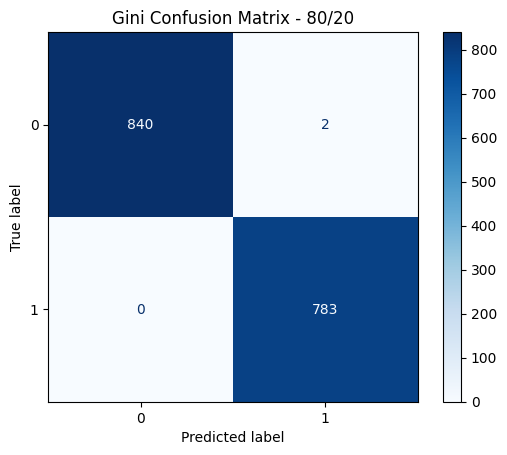

In [ ]:

# Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Select features using training data only
selector = SelectKBest(score_func=chi2, k=15)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Train Gini Decision Tree
gini_80 = DecisionTreeClassifier(criterion='gini', random_state=42)
gini_80.fit(X_train_selected, y_train)

# Evaluate
y_pred_80 = gini_80.predict(X_test_selected)
accuracy_80 = accuracy_score(y_test, y_pred_80)

print("Gini - 80/20 Split")
print("Accuracy:", accuracy_80)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_80))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_80, labels=[0, 1], cmap='Blues'
)
plt.title("Gini Confusion Matrix - 80/20")
plt.show()


Gini - 70/30 Split
Accuracy: 0.9975389663658737
Confusion Matrix:
[[1257    6]
 [   0 1175]]


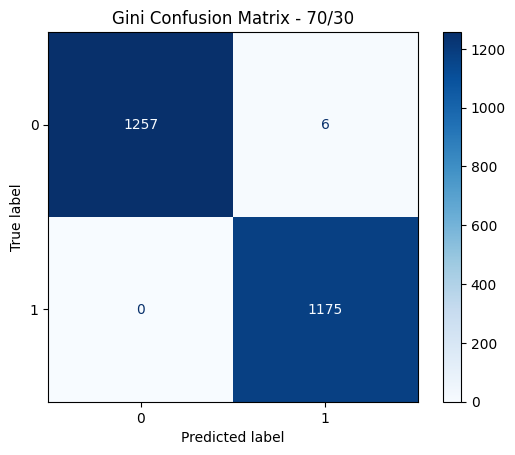

In [ ]:

# Split: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Select features using training data only
selector = SelectKBest(score_func=chi2, k=15)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Train Gini Decision Tree
gini_70 = DecisionTreeClassifier(criterion='gini', random_state=42)
gini_70.fit(X_train_selected, y_train)

# Evaluate
y_pred_70 = gini_70.predict(X_test_selected)
accuracy_70 = accuracy_score(y_test, y_pred_70)

print("Gini - 70/30 Split")
print("Accuracy:", accuracy_70)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_70))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_70, labels=[0, 1], cmap='Blues'
)
plt.title("Gini Confusion Matrix - 70/30")
plt.show()


### 6.2 Classification: Information Gain (entropy) <M3>

Entropy (IG) - 90/10 Split
Accuracy: 1.0
Confusion Matrix:
[[421   0]
 [  0 392]]


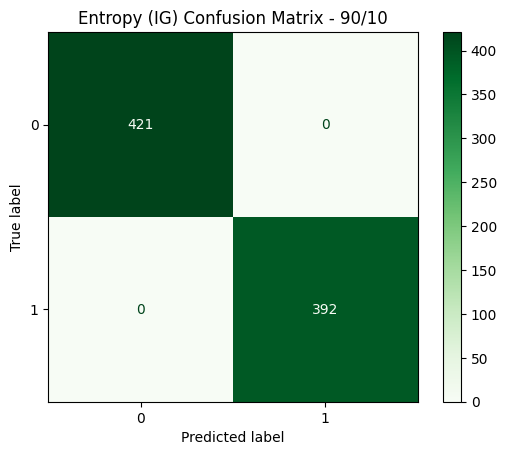

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use encoded data before feature selection
X = df_encoded.drop(columns=['poisonous'])
y = df_encoded['poisonous']

# Split: 90% training, 10% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)

# Select features using training data only
selector = SelectKBest(score_func=chi2, k=15)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Train Entropy (IG) Decision Tree
entropy_90 = DecisionTreeClassifier(criterion='entropy', random_state=42)
entropy_90.fit(X_train_selected, y_train)

# Evaluate
y_pred_ig_90 = entropy_90.predict(X_test_selected)
accuracy_ig_90 = accuracy_score(y_test, y_pred_ig_90)

print("Entropy (IG) - 90/10 Split")
print("Accuracy:", accuracy_ig_90)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ig_90))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_ig_90, labels=[0, 1], cmap='Greens'
)
plt.title("Entropy (IG) Confusion Matrix - 90/10")
plt.show()


Entropy (IG) - 80/20 Split
Accuracy: 0.9987692307692307
Confusion Matrix:
[[840   2]
 [  0 783]]


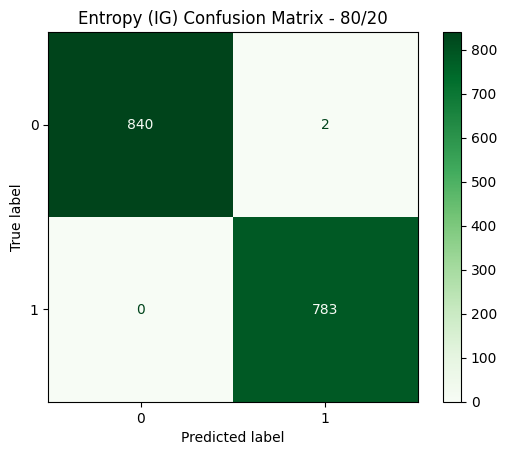

In [ ]:
# Split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Select features using training data only
selector = SelectKBest(score_func=chi2, k=15)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Train Entropy (IG) Decision Tree
entropy_80 = DecisionTreeClassifier(criterion='entropy', random_state=42)
entropy_80.fit(X_train_selected, y_train)

# Evaluate
y_pred_ig_80 = entropy_80.predict(X_test_selected)
accuracy_ig_80 = accuracy_score(y_test, y_pred_ig_80)

print("Entropy (IG) - 80/20 Split")
print("Accuracy:", accuracy_ig_80)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ig_80))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_ig_80, labels=[0, 1], cmap='Greens'
)
plt.title("Entropy (IG) Confusion Matrix - 80/20")
plt.show()


Entropy (IG) - 70/30 Split
Accuracy: 0.9975389663658737
Confusion Matrix:
[[1257    6]
 [   0 1175]]


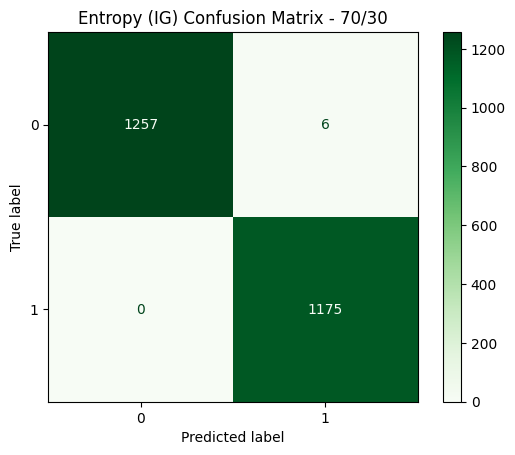

In [ ]:
# Split: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Select features using training data only
selector = SelectKBest(score_func=chi2, k=15)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Train Entropy (IG) Decision Tree
entropy_70 = DecisionTreeClassifier(criterion='entropy', random_state=42)
entropy_70.fit(X_train_selected, y_train)

# Evaluate
y_pred_ig_70 = entropy_70.predict(X_test_selected)
accuracy_ig_70 = accuracy_score(y_test, y_pred_ig_70)

print("Entropy (IG) - 70/30 Split")
print("Accuracy:", accuracy_ig_70)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ig_70))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_ig_70, labels=[0, 1], cmap='Greens'
)
plt.title("Entropy (IG) Confusion Matrix - 70/30")
plt.show()


### 6.3 Classification comparison <M5>
The following tables compare the classification accuracy of Gini Index and Information Gain (Entropy) across the three train/test partitions.

In [ ]:
print("Gini Index - Classification Accuracy")

gini_table = pd.DataFrame({
    '90/10': [accuracy_90],
    '80/20': [accuracy_80],
    '70/30': [accuracy_70]
}, index=['Accuracy'])

display(gini_table)

Gini Index - Classification Accuracy


,90/10,80/20,70/30
Accuracy,1.0,0.998769,0.997539


In [ ]:
print("Information Gain (Entropy) - Classification Accuracy")

ig_table = pd.DataFrame({
    '90/10': [accuracy_ig_90],
    '80/20': [accuracy_ig_80],
    '70/30': [accuracy_ig_70]
}, index=['Accuracy'])

display(ig_table)

Information Gain (Entropy) - Classification Accuracy


,90/10,80/20,70/30
Accuracy,1.0,0.998769,0.997539


**Interpretation (M5):** For each partition, Gini and Information Gain (Entropy) achieved the same accuracy. Therefore, there was no single best attribute selection measure for the 90/10, 80/20, or 70/30 partitions. Overall, neither measure outperformed the other because both produced identical accuracy and confusion matrix results across all partitions.

The confusion matrices show that all test instances were classified correctly in the 90/10 split. In the 80/20 split, two test instances were misclassified, while in the 70/30 split, six test instances were misclassified. These results indicate that both measures performed equally for the same partition, with the highest classification accuracy obtained using the 90/10 split.

### 6.4 Clustering: K-means <M4>
Three values of K were chosen to cover a small, a medium and a larger number of clusters: K = 2, 4 and 6. K = 2 matches the two known classes (edible and poisonous), so it shows whether the two classes appear on their own. K = 4 is a middle value that lets each class split into a few sub-groups while keeping every cluster large enough to describe. K = 6 tests whether finer structure exists, since attributes such as odor and habitat have seven to nine categories, and going much higher would give small clusters that are hard to interpret. The elbow plot covers K = 1 to 10, so these values can be compared against the whole curve.

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

features = df_processed.drop(columns=['poisonous'])
y_true = df_processed['poisonous']

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(features), columns=features.columns)

K_VALUES = [2, 4, 6]
kmeans_by_k, labels_by_k, rows = {}, {}, []

for k in K_VALUES:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans_result = kmeans.fit(X_scaled)
    kmeans_by_k[k] = kmeans_result
    labels_by_k[k] = kmeans_result.labels_
    rows.append({
        'K': k,
        'Avg silhouette width': silhouette_score(X_scaled, kmeans_result.labels_),
        'Total within-cluster SS': kmeans_result.inertia_,
        'Calinski-Harabasz': calinski_harabasz_score(X_scaled, kmeans_result.labels_),
        'Cluster sizes': sorted(np.bincount(kmeans_result.labels_).tolist(), reverse=True)
    })

results_df = pd.DataFrame(rows).set_index('K')
print("K-means results on %d records and %d features" % X_scaled.shape)
display(results_df.style.format({'Avg silhouette width': '{:.4f}','Total within-cluster SS': '{:,.2f}','Calinski-Harabasz': '{:,.2f}'}))

K-means results on 8124 records and 15 features


,Avg silhouette width,Total within-cluster SS,Calinski-Harabasz,Cluster sizes
K,,,,
2,0.3594,"81,520.56","4,019.07","[5032, 3092]"
4,0.4555,"43,786.71","4,826.09","[3816, 1796, 1296, 1216]"
6,0.4900,"32,218.98","4,517.25","[2040, 1796, 1440, 1296, 1216, 336]"


Elbow detected by KneeLocator at k = 4


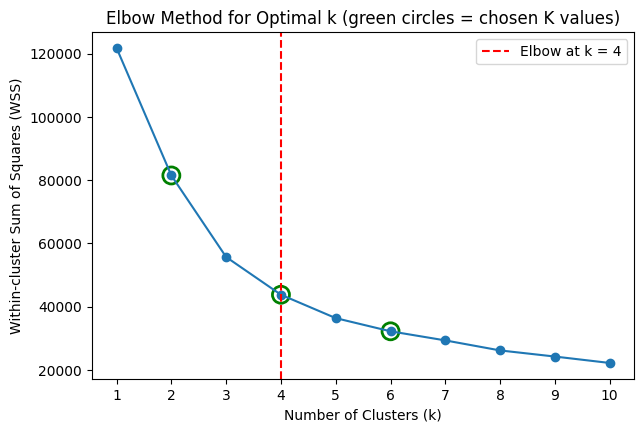

In [ ]:
%pip install kneed
import matplotlib.pyplot as plt
from kneed import KneeLocator

wss_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wss_values.append(kmeans.inertia_)

knee = KneeLocator(list(k_values), wss_values, curve='convex', direction='decreasing')
elbow_k = knee.elbow
print("Elbow detected by KneeLocator at k =", elbow_k)

plt.figure(figsize=(7, 4.5))
plt.plot(k_values, wss_values, marker='o')
for k in K_VALUES:
    plt.scatter(k, wss_values[k - 1], s=150, facecolors='none', edgecolors='green', linewidths=2)
if elbow_k is not None:
    plt.axvline(x=elbow_k, linestyle='--', color='red', label=f'Elbow at k = {elbow_k}')
plt.xticks(list(k_values))
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-cluster Sum of Squares (WSS)')
plt.title('Elbow Method for Optimal k (green circles = chosen K values)')
plt.legend()
plt.show()

K = 2: average silhouette score is 0.3593973636825338
K = 4: average silhouette score is 0.45549828006433857
K = 6: average silhouette score is 0.4899979611176674


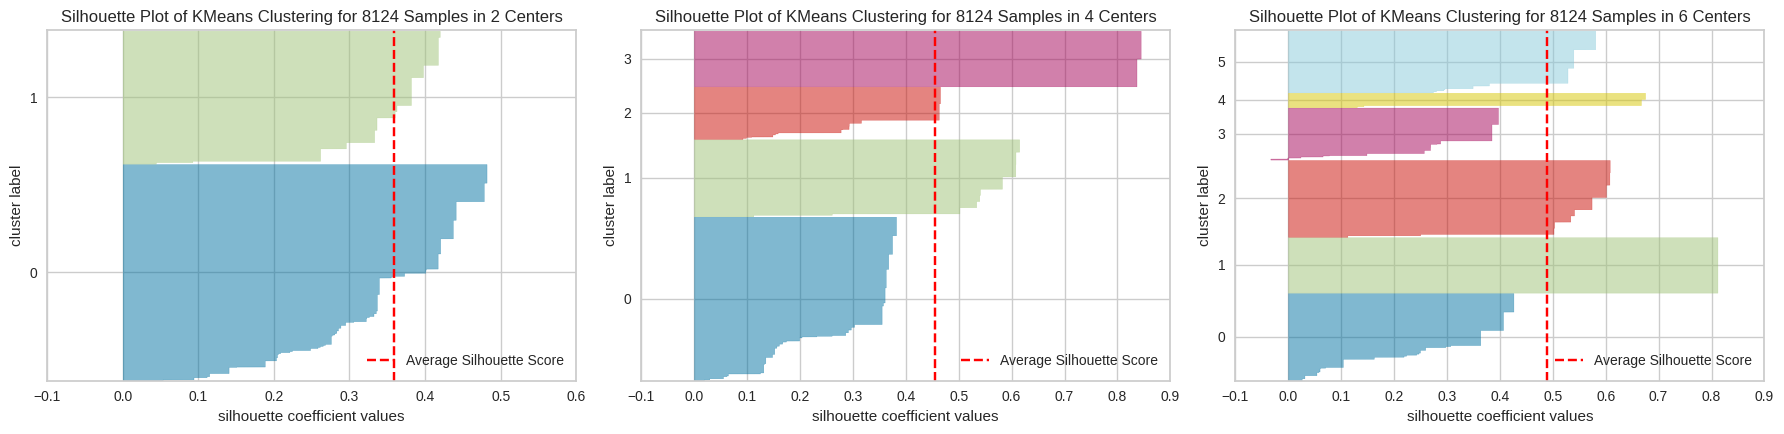

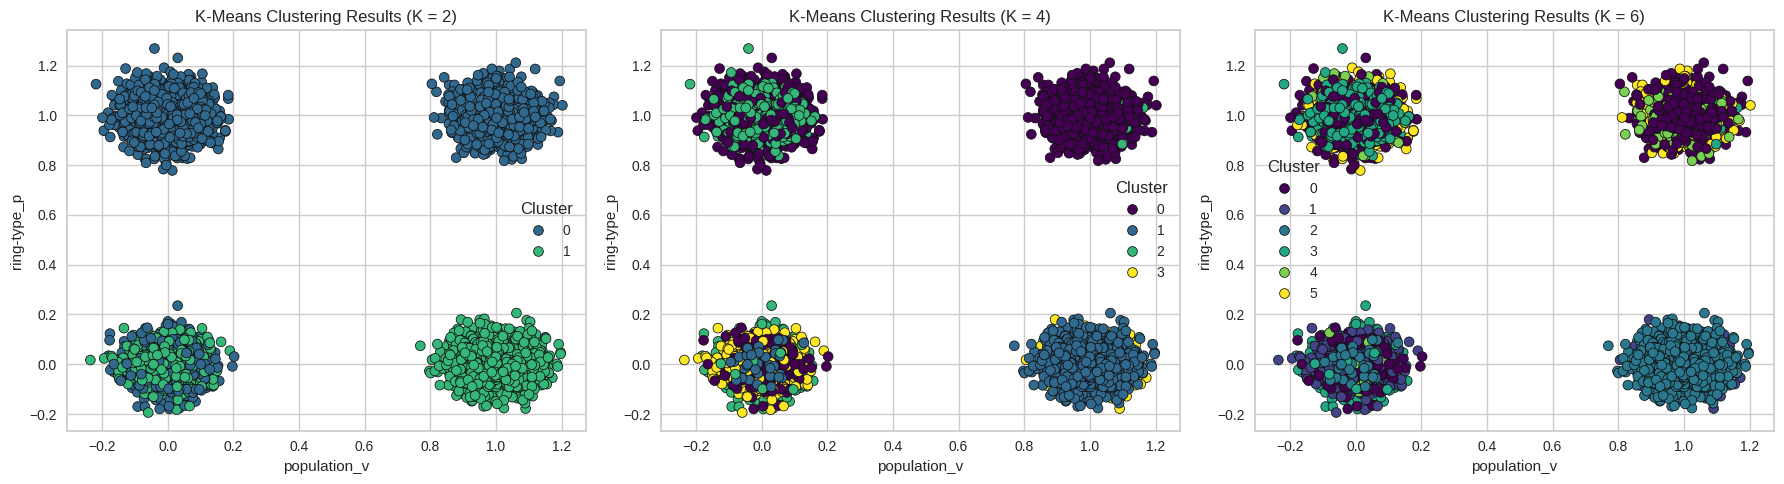

In [ ]:
%pip install yellowbrick seaborn
import seaborn as sns
from yellowbrick.cluster import SilhouetteVisualizer

fig, axes = plt.subplots(1, len(K_VALUES), figsize=(6 * len(K_VALUES), 4.5))
for ax, k in zip(axes, K_VALUES):
    visualizer = SilhouetteVisualizer(KMeans(n_clusters=k, n_init=10, random_state=42),colors='yellowbrick', ax=ax)
    visualizer.fit(X_scaled)
    print(f"K = {k}: average silhouette score is", visualizer.silhouette_score_)
    visualizer.finalize()
plt.tight_layout()
plt.show()


two_cols = features.mean().sub(0.5).abs().sort_values().index[:2]
jitter = np.random.RandomState(42).normal(0, 0.06, size=(len(features), 2))

fig, axes = plt.subplots(1, len(K_VALUES), figsize=(6 * len(K_VALUES), 5))
for ax, k in zip(axes, K_VALUES):
    plot_df = pd.DataFrame({
        two_cols[0]: features[two_cols[0]].values + jitter[:, 0],
        two_cols[1]: features[two_cols[1]].values + jitter[:, 1],
        'Cluster': labels_by_k[k]
    })
    sns.scatterplot(x=two_cols[0], y=two_cols[1], hue='Cluster', data=plot_df, palette='viridis', edgecolor='k', ax=ax)
    ax.set_title(f'K-Means Clustering Results (K = {k})')
plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter

#vote 1: highest average silhouette width
vote_sil = results_df['Avg silhouette width'].idxmax()
#vote 2: highest Calinski-Harabasz index
vote_ch = results_df['Calinski-Harabasz'].idxmax()
#vote 3: chosen K closest to the elbow
if elbow_k is None:
    vote_elbow = None
else:
    vote_elbow = min(K_VALUES, key=lambda k: (abs(k - elbow_k), k))

votes = {'Silhouette': vote_sil, 'Calinski-Harabasz': vote_ch, 'Elbow (WSS)': vote_elbow}
counts = Counter(v for v in votes.values() if v is not None)
top_k, top_n = counts.most_common(1)[0]

if top_n >= 2:
    best_k = top_k
    print(f"Majority rule: K = {best_k} wins with {top_n} of 3 votes.")
else:
    best_k = vote_sil
    print(f"No majority; falling back to the silhouette vote: K = {best_k}.")

summary = results_df.drop(columns=['Cluster sizes']).copy()
summary['Votes'] = [sum(v == k for v in votes.values()) for k in summary.index]
display(summary.style.format({'Avg silhouette width': '{:.4f}','Total within-cluster SS': '{:,.2f}', 'Calinski-Harabasz': '{:,.2f}'}))
print(votes)

Majority rule: K = 4 wins with 2 of 3 votes.


,Avg silhouette width,Total within-cluster SS,Calinski-Harabasz,Votes
K,,,,
2,0.3594,"81,520.56","4,019.07",0
4,0.4555,"43,786.71","4,826.09",2
6,0.4900,"32,218.98","4,517.25",1


{'Silhouette': np.int64(6), 'Calinski-Harabasz': np.int64(4), 'Elbow (WSS)': 4}


**Best K by majority rule <M4>:** K = 4 was selected as the best K, with 2 of 3 votes. The Calinski-Harabasz index was highest at K = 4 (4,826.09), and the elbow of the WSS curve also pointed to K = 4. The average silhouette width was highest at K = 6 (0.4900), followed by K = 4 (0.4555) and K = 2 (0.3594), so the silhouette vote went to K = 6. K = 2 received no votes, with the lowest silhouette (0.3594) and Calinski-Harabasz (4,019.07). The total within-cluster sum of squares decreased as K increased (81,520.56 for K = 2, 43,786.71 for K = 4, and 32,218.98 for K = 6), as expected, so it was used only through the elbow.

### 6.5 Clustering interpretation <M6>

In [ ]:
# Compare the class composition of the clusters.

class_names = {0: 'Edible', 1: 'Poisonous'}

for k in K_VALUES:
    comparison = pd.DataFrame({
        'Cluster': labels_by_k[k],
        'Class': y_true.map(class_names).values
    })

    counts = pd.crosstab(comparison['Cluster'], comparison['Class'])
    percentages = pd.crosstab(
        comparison['Cluster'], comparison['Class'], normalize='index'
    ) * 100

    print(f'K = {k}: number of mushrooms in each class per cluster')
    display(counts)
    print(f'K = {k}: class percentages within each cluster')
    display(percentages.round(2))

    cluster_sizes = comparison['Cluster'].value_counts().sort_index()
    poisonous_percent = percentages['Poisonous'] if 'Poisonous' in percentages else pd.Series(0, index=percentages.index)
    summary = pd.DataFrame({
        'Cluster size': cluster_sizes,
        'Poisonous (%)': poisonous_percent
    })
    display(summary.round(2))


K = 2: number of mushrooms in each class per cluster


Class,Edible,Poisonous
Cluster,,
0,4208,824
1,0,3092


K = 2: class percentages within each cluster


Class,Edible,Poisonous
Cluster,,
0,83.62,16.38
1,0.00,100.00


,Cluster size,Poisonous (%)
Cluster,,
0,5032,16.38
1,3092,100.00


K = 4: number of mushrooms in each class per cluster


... (5 outputs left out)

Class,Edible,Poisonous
Cluster,,
0,1792,248
1,0,1296
2,0,1796
3,1104,112
4,48,288
5,1264,176


K = 6: class percentages within each cluster


Class,Edible,Poisonous
Cluster,,
0,87.84,12.16
1,0.00,100.00
2,0.00,100.00
3,90.79,9.21
4,14.29,85.71
5,87.78,12.22


,Cluster size,Poisonous (%)
Cluster,,
0,2040,12.16
1,1296,100.00
2,1796,100.00
3,1216,9.21
4,336,85.71
5,1440,12.22


K = 2: cluster feature profile (top distinguishing features)


Cluster,0,1
ring-type_p,0.789,0.000
stalk-surface-above-ring_k,0.029,0.721
odor_n,0.695,0.010
bruises,0.671,0.000
stalk-surface-below-ring_k,0.029,0.699
gill-color_b,0.000,0.559
odor_f,0.057,0.605
spore-print-color_w,0.118,0.581


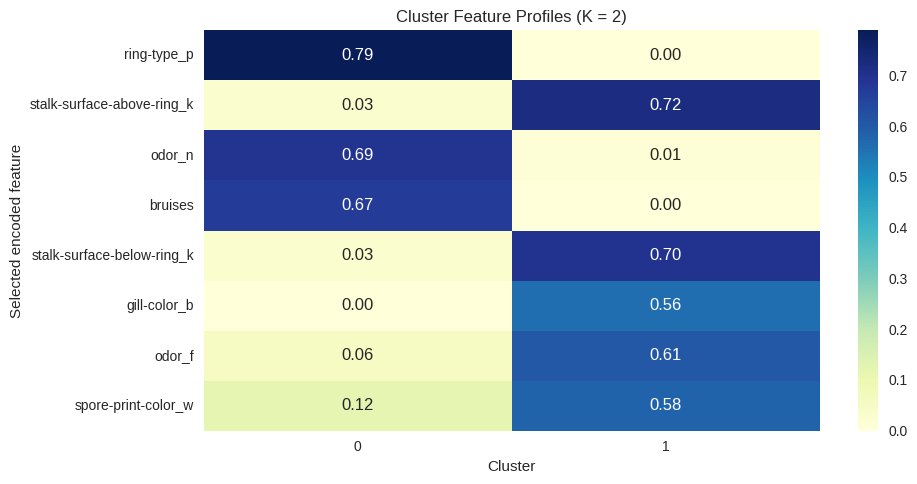

K = 4: cluster feature profile (top distinguishing features)


Cluster,0,1,2,3
gill-spacing,0.025,0.000,1.000,0.0
stalk-surface-above-ring_k,0.000,0.519,0.118,1.0
odor_f,0.075,0.321,0.000,1.0
spore-print-color_w,0.063,1.000,0.289,0.0
spore-print-color_h,0.088,0.000,0.000,1.0
ring-type_l,0.000,0.000,0.000,1.0
stalk-surface-below-ring_k,0.000,0.481,0.118,1.0
gill-size,0.155,0.980,0.132,0.0


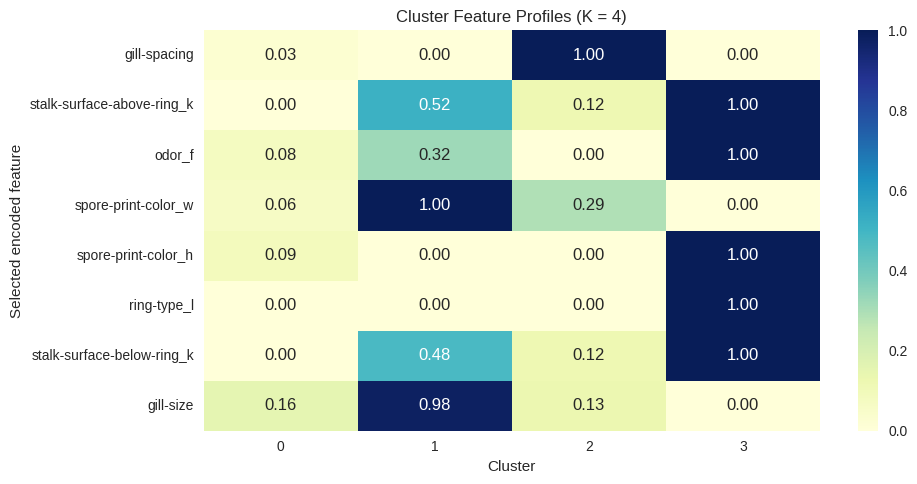

K = 6: cluster feature profile (top distinguishing features)


Cluster,0,1,2,3,4,5
gill-spacing,0.047,0.0,0.000,1.000,0.000,0.0
stalk-surface-above-ring_k,0.000,1.0,0.519,0.118,0.000,0.0
odor_f,0.000,1.0,0.321,0.000,0.857,0.0
spore-print-color_h,0.000,1.0,0.000,0.000,1.000,0.0
ring-type_p,0.906,0.0,0.000,0.322,0.857,1.0
ring-type_l,0.000,1.0,0.000,0.000,0.000,0.0
stalk-surface-below-ring_k,0.000,1.0,0.481,0.118,0.000,0.0
spore-print-color_k,0.000,0.0,0.000,0.355,0.000,1.0


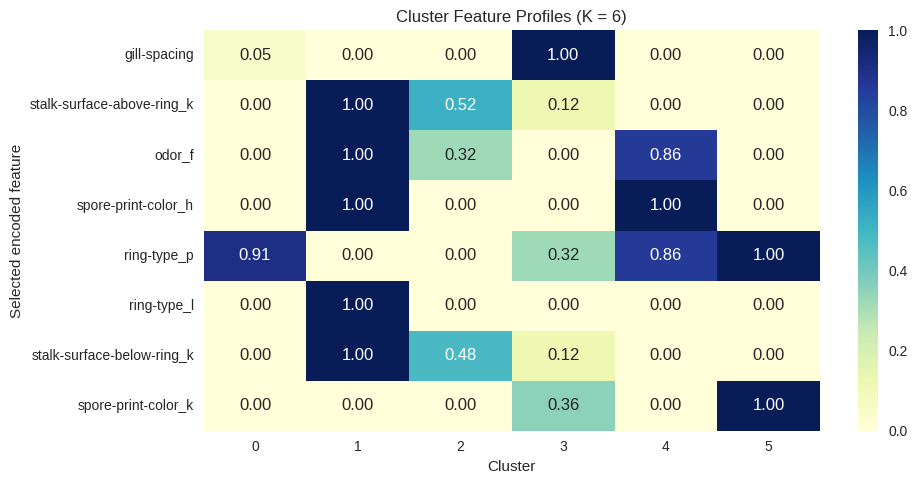

In [ ]:
# Compare the encoded feature proportions across clusters.

import seaborn as sns
import matplotlib.pyplot as plt

cluster_profiles = {}

for k in K_VALUES:
    profile_data = features.copy()
    profile_data['Cluster'] = labels_by_k[k]
    profile = profile_data.groupby('Cluster').mean()
    cluster_profiles[k] = profile

    feature_spread = profile.max(axis=0) - profile.min(axis=0)
    top_features = feature_spread.sort_values(ascending=False).head(8).index
    selected_profile = profile[top_features]

    print(f'K = {k}: cluster feature profile (top distinguishing features)')
    display(selected_profile.T.round(3))

    plt.figure(figsize=(10, 5))
    sns.heatmap(selected_profile.T, annot=True, fmt='.2f', cmap='YlGnBu')
    plt.title(f'Cluster Feature Profiles (K = {k})')
    plt.xlabel('Cluster')
    plt.ylabel('Selected encoded feature')
    plt.tight_layout()
    plt.show()

**Interpretation of each K <M6>:**

**K = 2**

For K = 2, Cluster 1 contained 3,092 mushrooms and all of them were poisonous (100%). Cluster 0 contained 5,032 mushrooms, of which 83.62% were edible and 16.38% were poisonous. The feature profiles show that Cluster 0 had a high proportion of mushrooms with no odor (`odor_n`, 69.5%) and the encoded `ring-type_p` feature (78.9%). Cluster 1 had higher proportions of `stalk-surface-above-ring_k` (72.1%), `stalk-surface-below-ring_k` (69.9%), and foul odor (`odor_f`, 60.5%). This solution separates one fully poisonous group, while the other cluster still contains both classes.

**K = 4**

For K = 4, Clusters 1 and 3 contained only poisonous mushrooms. Cluster 1 included 1,796 mushrooms, while Cluster 3 included 1,296. Clusters 0 and 2 were mostly edible: 81.34% of Cluster 0 and 90.79% of Cluster 2 were edible. The feature profiles also show differences between the groups. For example, `spore-print-color_w` appeared in all records in Cluster 1 (100%), and `gill-size` appeared in 98% of that cluster. Cluster 3 had `odor_f`, `spore-print-color_h`, and `ring-type_l` at 100%. Cluster 2 had `gill-spacing` at 100%. These patterns make the four groups easier to describe, although Clusters 0 and 2 still include some poisonous mushrooms.

**K = 6**

For K = 6, Clusters 1 and 2 contained only poisonous mushrooms. Cluster 4 contained 336 mushrooms, of which 85.71% were poisonous. Clusters 0, 3, and 5 were mainly edible, with edible proportions of 87.84%, 90.79%, and 87.78%, respectively. In the feature profiles, Cluster 4 had high proportions of `odor_f`, `spore-print-color_h`, and `ring-type_p` (85.7% each). Cluster 1 had `odor_f`, `spore-print-color_h`, and `ring-type_l` at 100%. This solution gives more detail than K = 4, but it also creates an additional smaller mixed cluster (Cluster 4).

**Overall interpretation**

All three solutions produced clusters with different edible/poisonous compositions and distinguishable feature profiles. K = 4 was selected by the project's majority-rule evaluation, while K = 6 achieved the highest silhouette score. The cluster comparison shows that K = 4 provides a useful balance: two clusters are entirely poisonous, and the other two are mostly edible. However, none of these results should be treated as a perfect classification of mushroom edibility.

## [7] Findings and Discussion



### Classification findings <M5>
The following Gini Decision Tree using the 90/10 partition and the feature importance table present the final representative classification model and the most important features used in the classification process.

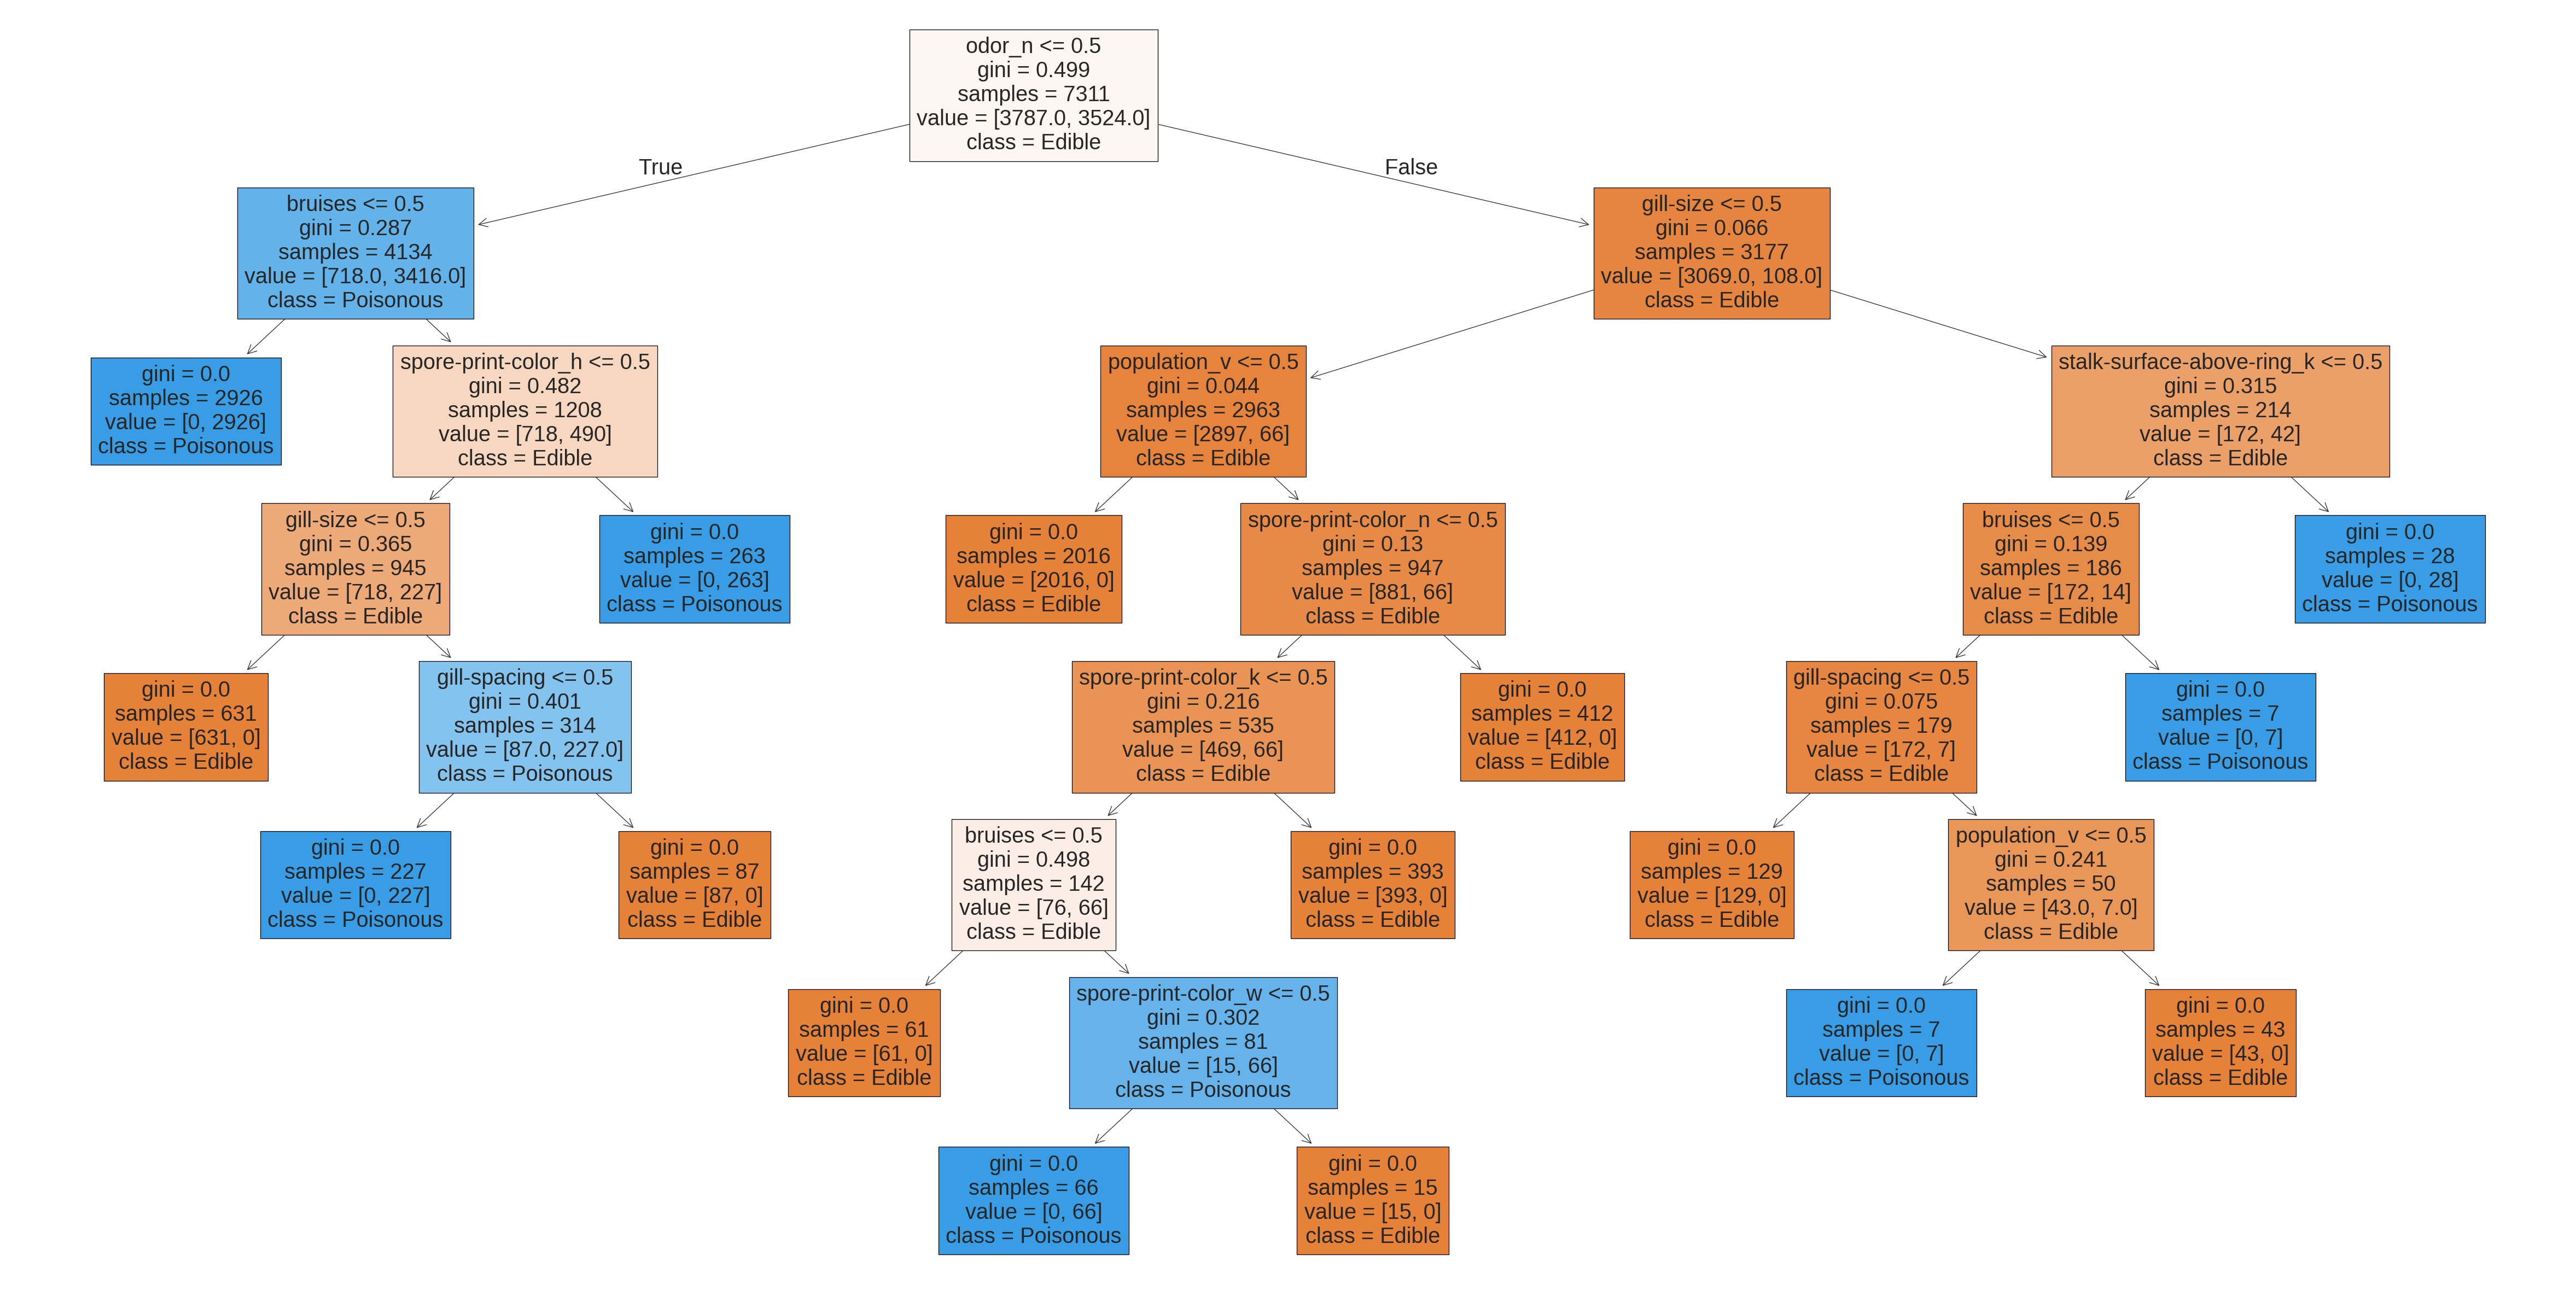

In [ ]:
from sklearn import tree

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)

selector_final = SelectKBest(score_func=chi2, k=15)
X_train_final = selector_final.fit_transform(X_train, y_train)

final_feature_names = X.columns[selector_final.get_support()]

final_tree = DecisionTreeClassifier(criterion='gini', random_state=42)
final_tree.fit(X_train_final, y_train)

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(20, 10), dpi=300)

tree.plot_tree(
    final_tree,
    feature_names=final_feature_names,
    class_names=['Edible', 'Poisonous'],
    filled=True
)

plt.show()


In [ ]:
feature_importance = pd.DataFrame({
    'Feature': final_feature_names,
    'Importance': final_tree.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
4,odor_n,0.617820
0,bruises,0.181538
10,spore-print-color_h,0.065066
2,gill-size,0.063339
1,gill-spacing,0.034843
11,spore-print-color_k,0.012345
6,stalk-surface-above-ring_k,0.011401
13,spore-print-color_w,0.006696
14,population_v,0.005012
12,spore-print-color_n,0.001941


Both Gini Index and Information Gain (Entropy) achieved identical results for all three partitions. The highest accuracy was obtained with the 90/10 partition, where both achieved an accuracy of 1.0. Therefore, there was no single best attribute selection measure. The Gini model with the 90/10 partition was selected as a representative final Decision Tree from the tied best-performing models.

The final Decision Tree shows that odor_n was the most important feature, followed by bruises, spore-print-color_h, gill-size, and gill-spacing. odor_n was also used at the root of the tree, showing its strong role in separating edible and poisonous mushrooms. Several branches reached pure leaf nodes with a Gini value of 0.0, indicating clear separation between the two classes.

### Comparison with the selected research paper <M5>
For classification, our Decision Tree models achieved accuracies of 1.0, 0.9988, and 0.9975 for the 90/10, 80/20, and 70/30 partitions, respectively. Ortiz-Letechipia et al. [2] also reported very high classification performance on the Mushroom dataset. Their XGBoost model with LASSO-selected features achieved a perfect accuracy of 1.0, while KNN achieved an accuracy higher than 0.99. Both studies also identified odor as an important feature for distinguishing mushroom toxicity. Therefore, our results are consistent with the strong classification performance reported in [2]. However, the results are not directly comparable because different classification algorithms, feature selection methods, and evaluation procedures were used.

### Clustering findings <M6>

The results show that the number of clusters changes how the mushrooms are grouped. The majority-rule evaluation selected **K = 4**, because both the Calinski-Harabasz index and the elbow method favored this value. K = 6 had the highest silhouette score (0.4900), compared with 0.4555 for K = 4. However, the project used the majority rule rather than the silhouette score alone. The Calinski-Harabasz score was also highest at K = 4 (4,826.09).

The class-composition results help explain the clusters. With K = 2, one cluster was entirely poisonous, while the other was mostly edible (83.62%). With K = 4, two clusters were entirely poisonous, and the other two were mostly edible (81.34% and 90.79%). With K = 6, two clusters were entirely poisonous and another smaller cluster was 85.71% poisonous; the remaining three clusters were mostly edible. This shows that the clustering captures useful patterns related to mushroom characteristics, but it does not separate every edible and poisonous mushroom perfectly.

The feature profiles also show differences between clusters. Odor-related features, spore-print-color indicators, gill size, gill spacing, and ring-type indicators were among the features that distinguished the groups. For example, the foul-odor feature (`odor_f`) was present in 100% of K = 4 Cluster 3, while `spore-print-color_w` was present in 100% of K = 4 Cluster 1. These are proportions within each cluster, not classification accuracy values.

Overall, **K = 4 is the preferred solution under the project's majority-rule criterion**. It provides more detail than K = 2 and avoids creating as many groups as K = 6. K = 6 has the strongest silhouette score, so it may be useful when the goal is to examine more detailed subgroups. The choice of K = 4 is therefore based on the combined evaluation measures and the interpretability of the resulting groups, not on a claim that it perfectly identifies mushroom toxicity.

**Methodological limitation:** The `poisonous` column was not included directly in the K-Means input. However, the 15 input features had previously been selected using `SelectKBest(chi2)` with `poisonous` as the target. This means the class label influenced feature selection before clustering. The cluster-label comparison should therefore be interpreted with this limitation in mind.

### Comparison with the selected research paper *(M6)*

Xu and Wunsch [1] reviewed clustering methods on the Mushroom dataset and reported that traditional K-Means performed poorly on the original categorical data, with an accuracy of approximately 69% in the study they cited. They also discussed that methods designed for categorical data can produce better groupings. This is relevant to our project because the Mushroom dataset contains many categorical characteristics, and applying K-Means with Euclidean distance may not fully represent the relationships between categories.

Our project used one-hot/binary encoding, selected 15 features, standardized them, and compared K = 2, 4, and 6 using silhouette score, WCSS/elbow, and the Calinski-Harabasz index. K = 4 was selected by the majority rule. The approximately 69% accuracy reported in [1] is not directly comparable with our silhouette score or WCSS: accuracy measures agreement with known class labels, while silhouette and WCSS evaluate the structure of the clusters. The comparison is therefore about the methods and dataset, not a direct numerical comparison.

The study by Ortiz-Letechipia et al. [2] also identified odor, spore-print color, and gill size as useful features for toxicity classification. These characteristics appear in our selected feature set and in the cluster profiles. This supports examining them when describing the groups. However, [2] used supervised classification, while our project used unsupervised K-Means, so its findings provide context rather than proof that our clusters classify toxicity.

### Comparison with the selected research paper

Xu and Wunsch [1] reviewed clustering methods on the Mushroom dataset and reported that traditional K-Means performed poorly on the original categorical data, with an accuracy of approximately 69% in the study they cited. They also discussed that methods designed for categorical data can produce better groupings. This is relevant to our project because the Mushroom dataset contains many categorical characteristics, and applying K-Means with Euclidean distance may not fully represent the relationships between categories.

Our project used one-hot/binary encoding, selected 15 features, standardized them, and compared K = 2, 4, and 6 using silhouette score, WCSS/elbow, and the Calinski-Harabasz index. K = 4 was selected by the majority rule. The approximately 69% accuracy reported in [1] is not directly comparable with our silhouette score or WCSS: accuracy measures agreement with known class labels, while silhouette and WCSS evaluate the structure of the clusters. The comparison is therefore about the methods and dataset, not a direct numerical comparison.

The study by Ortiz-Letechipia et al. [2] also identified odor, spore-print color, and gill size as useful features for toxicity classification. These characteristics appear in our selected feature set and in the cluster profiles. This supports examining them when describing the groups. However, [2] used supervised classification, while our project used unsupervised K-Means, so its findings provide context rather than proof that our clusters classify toxicity.

## [8] References <M6>

[1] R. Xu and D. C. Wunsch II, “Survey of clustering algorithms,” *IEEE Transactions on Neural Networks*, vol. 16, no. 3, pp. 645–678, May 2005, doi: 10.1109/TNN.2005.845141.

[2] J. S. Ortiz-Letechipia, C. E. Galvan-Tejada, J. I. Galván-Tejada, M. A. Soto-Murillo, E. Acosta-Cruz, H. Gamboa-Rosales, J. M. Celaya Padilla, and H. Luna-García, “Classification and selection of the main features for the identification of toxicity in *Agaricus* and *Lepiota* with machine learning algorithms,” *PeerJ*, vol. 12, Art. no. e16501, Jan. 2024, doi: 10.7717/peerj.16501.

[3] “Mushroom,” UCI Machine Learning Repository, 1981, doi: 10.24432/C5959T.
